<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1109_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5.3. 전이 학습

합성곱 신경망 기반의 딥러닝 모델을 제대로 훈련시키기위해서는, 많은 양의 데이터 필요.

현실적인 어려움

--> 전이 학습

전이 학습: 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용

사전 훈련된 모델: 아주 큰 데이터셋을 사용하여 훈련된 모델

문제 A --> 문제 A를 해결하면서 얻은 지식 및 경험 --> 문제 B (적용, 전이 학습)





# 특성 추출 기법

특성 추출: ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 완전연결층 부분만 새로 생성

: 마지막 완전연결층만 학습, 나머지 계층 학습 X

- 합성곱층: 합성곱층, 풀링층으로 구성

- 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분

: 사전 훈련된 네트워크의 합성곱층에 새로운 데이터를 통과시키고, 그 출력을 데이터 분류기에서 훈련시킴.

: 사용 가능한 이미지 분류 모델 - XCeoption, Inception V3, ResNet50, VGG16, VGG19, MobileNet








In [3]:
pip install opencv-python

openCV: 오픈 소스 컴퓨터 비전 라이브러리

In [4]:
# 5-12. 라이브러리 호출
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision # 컴퓨터 비전 용도의 패키지
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용되는 패키지
import torchvision.models as models # 다양한 파이토치 네트워크를 사용할 수 있도록 도와주는 패키지
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [6]:
# 압축 풀기
import zipfile
import os

with zipfile.ZipFile('/content/train.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/data')

print(os.listdir('/content/data'))

['train']


In [9]:
import os
import zipfile

with zipfile.ZipFile('/content/test1.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/data')

print(os.listdir('/content/data'))

['train', 'test1']


In [40]:
import os
import shutil

test_path = '/content/data/test1'
target_path = '/content/data/test1/test'

os.makedirs(target_path, exist_ok=True)

for filename in os.listdir(test_path):
    src = os.path.join(test_path, filename)
    dst = os.path.join(target_path, filename)

    if filename.lower().endswith('.jpg') and os.path.isfile(src):
        shutil.move(src, dst)

print('이동 완료!')
print('이미지 개수:', len(os.listdir(target_path)))

이동 완료!
이미지 개수: 12500


In [8]:
import os

print(os.listdir('/content/data/train')[:20])

['dog.12366.jpg', 'cat.800.jpg', 'cat.10711.jpg', 'dog.7417.jpg', 'dog.10842.jpg', 'cat.12227.jpg', 'cat.9673.jpg', 'cat.8514.jpg', 'dog.2814.jpg', 'dog.11628.jpg', 'cat.3875.jpg', 'cat.541.jpg', 'dog.2078.jpg', 'dog.1565.jpg', 'cat.11493.jpg', 'dog.1254.jpg', 'dog.10383.jpg', 'cat.9388.jpg', 'dog.3042.jpg', 'dog.798.jpg']


In [10]:
import os
import shutil

train_path = '/content/data/train'

os.makedirs(f'{train_path}/cat', exist_ok=True)
os.makedirs(f'{train_path}/dog', exist_ok=True)

for filename in os.listdir(train_path):
    src = os.path.join(train_path, filename)

    if not os.path.isfile(src):
        continue

    if filename.startswith('cat.'):
        shutil.move(src, f'{train_path}/cat/{filename}')

    elif filename.startswith('dog.'):
        shutil.move(src, f'{train_path}/dog/{filename}')

print('고양이:', len(os.listdir(f'{train_path}/cat')))
print('강아지:', len(os.listdir(f'{train_path}/dog')))

고양이: 12500
강아지: 12500


In [11]:
# 5-13. 이미지 데이터 전처리 방법 정의
data_path='/content/data/train' # 이미지 데이터가 위치한 경로 지정

transform=transforms.Compose(
    [
        transforms.Resize([256, 256]),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor()
    ])
train_dataset=torchvision.datasets.ImageFolder(
    data_path,
    transform=transform
)
train_loader=torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8,
    shuffle=True
)

print(len(train_dataset))

25000


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


- torchvision.transform: 이미지 데이터를 변환하여 모델의 입력으로 사용할 수 있도록 변환

- Resize: 이미지의 크기 조정

- RandomResizedCrop: 이미지를 랜덤한 크기 및 비율로 자름.

Resize: 합성곱층을 통과하기 위해 이미지 크기를 조정하는 전처리 과정

RandomResizedCrop: 데이터 확장 용도 / 이미지를 랜덤한 비율로 자른 후 데이터 크기 조정

- RandomHorizontalFlip: 이미지를 랜덤하게 수평으로 뒤집음.

- ToTensor: 이미지 데이터를 텐서로 변환

- dataset.sImageFolder: 데이터로더가 데이터를 불러올 대상, 방법 정의

(파라미터: 불러올 데이터가 위치한 경로, transform(이미지 데이터에 대한 전처리))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


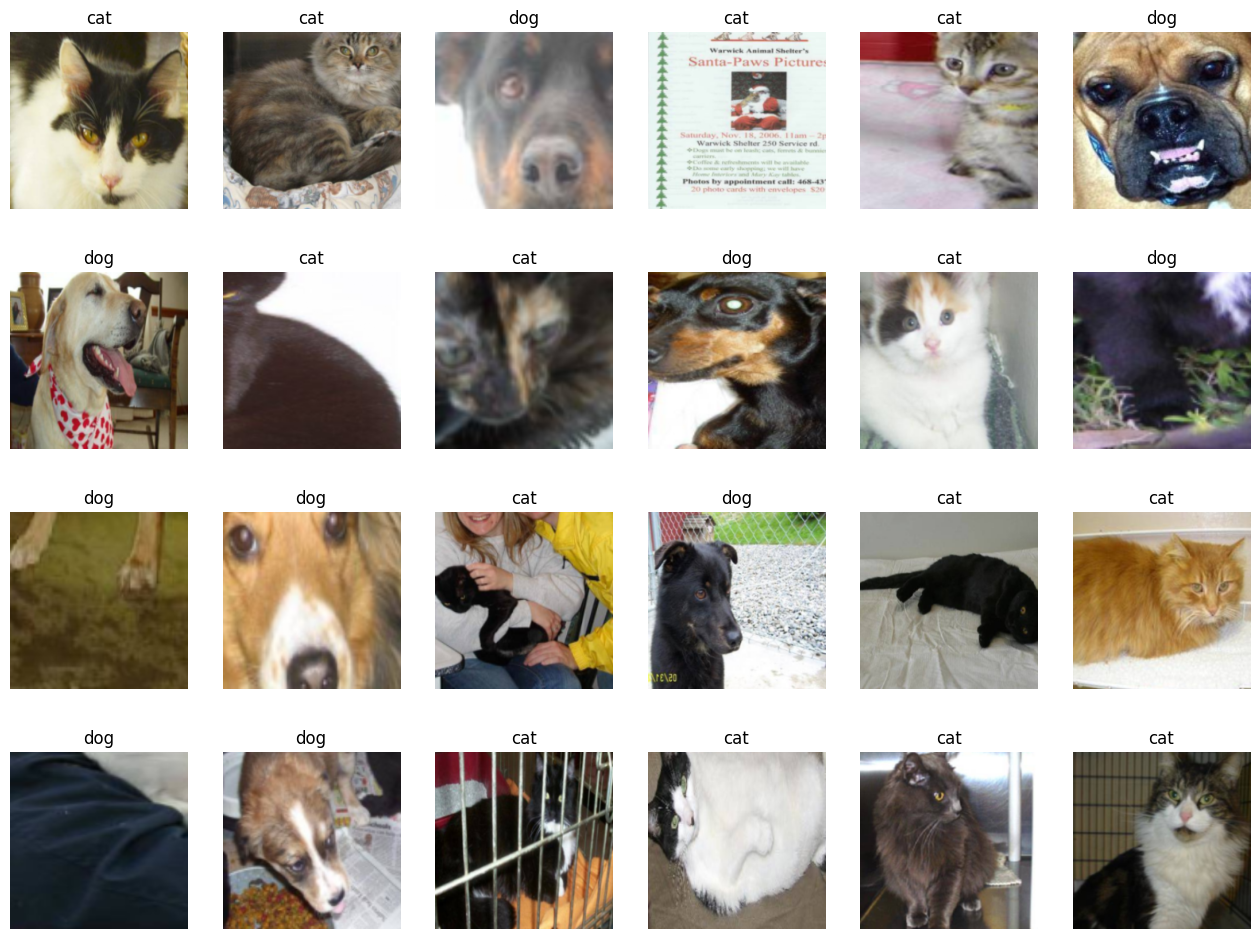

In [13]:
# 5-14. 학습에 사용될 이미지 출력
import numpy as np
samples, labels=next(iter(train_loader))
classes={0:'cat', 1:'dog'} # 개, 고양이에 대한 클래스로 구성
fig=plt.figure(figsize=(16,24))
for i in range(24): # 24개의 이미지 데이터 출력
  a=fig.add_subplot(4, 6, i+1)
  a.set_title(classes[labels[i].item()]) # 레이블 정보를 함께 출력
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

- iter(): 전달된 데이터의 반복자 꺼내 반환

- next(): 그 반복자가 다음에 출력해야 할 요소 반환

- train_loader에서 samples, labels 값 순차적으로 꺼내서 저장

- np.transpose: 행렬의 차원 change



In [14]:
# 5-15. 사전 훈련된 모델 내려받기
resnet18=models.resnet18(pretrained=True) # pretrained=True는 사전 학습된 가중치를 사용하겠다는 의미



/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


In [16]:
# 5-16. 사전 훈련된 모델의 파라미터 학습 유무 지정
def set_parameter_requires_grad(model, feature_extracting=True):
  if feature_extracting:
    for param in model.parameters():
      param.requires_grad=False
set_parameter_requires_grad(resnet18)

- param.required_grad=False: 역전파 중 파라미터들에 대한 변화를 계산할 필요가 없음.

- ResNet18의 마지막 부분에 완전연결층 추가

추가된 완전연결층: 개, 고양이 클래스 분류 용도



In [17]:
# 5-17. ResNet18에 완전연결층 추가
resnet18.fc=nn.Linear(512, 2) # 2는 클래스가 두 개라는 의미

In [18]:
# 5-18. 모델의 파라미터 값 확인
for name, param in resnet18.named_parameters():
  if param.requires_grad:
    print(name, param.data)

fc.weight tensor([[-0.0113,  0.0163, -0.0205,  ...,  0.0186, -0.0188, -0.0028],
        [ 0.0247, -0.0253, -0.0183,  ..., -0.0225,  0.0241,  0.0399]])
fc.bias tensor([-0.0422, -0.0101])


In [19]:
# 5-19. 모델 객체 생성 및 손실 함수 정의
model=models.resnet18(pretrained=True)

for param in model.parameters():
  param.requires_grad=False

model.fc=torch.nn.Linear(512, 2)
for param in model.fc.parameters():
  param.requires_grad=True

optimizer=torch.optim.Adam(model.fc.parameters())
cost=torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [34]:
# 5-20. 모델 학습을 위한 함수 생성
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13,
                is_train=True):
  since=time.time()
  acc_history=[]
  loss_history=[]
  best_acc=0.0

  for epoch in range(num_epochs):
    print('Epoch {}/{}'.format(epoch, num_epochs-1))
    print('-' * 10)

    running_loss=0.0
    running_corrects=0

    for inputs, labels in dataloaders:
      inputs=inputs.to(device)
      labels=labels.to(device)

      model.to(device)
      optimizer.zero_grad()
      outputs=model(inputs)
      loss=criterion(outputs, labels)
      _, preds=torch.max(outputs, 1)
      loss.backward()
      optimizer.step()

      running_loss+=loss.item()*inputs.size(0)
      running_corrects+=torch.sum(preds==labels.data)
    epoch_loss=running_loss/len(dataloaders.dataset)
    epoch_acc=running_corrects.double()/len(dataloaders.dataset)

    print('Loss: {:.4f} Acc:{:.4f}'.format(epoch_loss, epoch_acc))

    if epoch_acc>best_acc:
      best_acc=epoch_acc

    acc_history.append(epoch_acc.item())
    loss_history.append(epoch_loss)
    os.makedirs('/content/checkpoints', exist_ok=True)
    torch.save(model.state_dict(), os.path.join('/content/checkpoints',
                                            '{0:0=2d}.pth'.format(epoch)))
    print()

  time_elapsed=time.time()-since
  print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed//60,
                                                      time_elapsed%60))
  print('Best Acc: {:4f}'.format(best_acc))
  return acc_history, loss_history



In [35]:
# 코드 5-21. 파라미터 학습 결과를 옵티마이저에 전달
params_to_update=[]
for name, param in resnet18.named_parameters():
  if param.requires_grad==True:
    params_to_update.append(param)
    print("\t", name)

optimzer=optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [36]:
# 5-22. 모델 학습
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion=nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist=train_model(resnet18, train_loader, criterion,
                                            optimizer, device)

Epoch 0/12
----------
Loss: 0.6503 Acc:0.6206

Epoch 1/12
----------
Loss: 0.6492 Acc:0.6191

Epoch 2/12
----------
Loss: 0.6494 Acc:0.6203

Epoch 3/12
----------
Loss: 0.6520 Acc:0.6138

Epoch 4/12
----------
Loss: 0.6487 Acc:0.6197

Epoch 5/12
----------
Loss: 0.6493 Acc:0.6202

Epoch 6/12
----------
Loss: 0.6504 Acc:0.6130

Epoch 7/12
----------
Loss: 0.6510 Acc:0.6180

Epoch 8/12
----------
Loss: 0.6491 Acc:0.6189

Epoch 9/12
----------
Loss: 0.6503 Acc:0.6198

Epoch 10/12
----------
Loss: 0.6503 Acc:0.6187

Epoch 11/12
----------
Loss: 0.6486 Acc:0.6193

Epoch 12/12
----------
Loss: 0.6490 Acc:0.6207

Training complete in 25m 30s
Best Acc: 0.620720


In [41]:
# 코드 5-23. 테스트 데이터 호출 및 전처리
test_path='/content/data/test1'

transform=transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor()
])
test_dataset=torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader=torch.utils.data.DataLoader(
        test_dataset,
        batch_size=32,
        num_workers=1,
        shuffle=True
    )
print(len(test_dataset))


12500


In [46]:
# 5-24. 테스트 데이터 평가 함수 생성
def eval_model(model, dataloaders, device):
  since=time.time()
  acc_history=[]
  best_acc=0.0

  saved_models = glob.glob('/content/checkpoints/*.pth')
  saved_models.sort()
  print('saved_model', saved_models)

  for model_path in saved_models:
    print('Loading model', model_path)

    model.load_state_dict(torch.load(model_path))
    model.eval()
    model.to(device)
    running_corrects=0

    for inputs, labels in dataloaders:
      inputs=inputs.to(device)
      labels=labels.to(device)

      with torch.no_grad():
        outputs=model(inputs)

      _, preds=torch.max(outputs.data, 1)
      preds[preds>=0.5]=1
      preds[preds<0.5]=0
      running_corrects += preds.eq(labels).int().sum()

    epoch_acc=running_corrects.double()/len(dataloaders.dataset)
    print('Acc: {:.4f}'.format(epoch_acc))

    if epoch_acc>best_acc:
      best_acc=epoch_acc
      acc_history.append(epoch_acc.item())
      print()

    time_elapsed=time.time()-since
    print('Validation complete in {:.0f}s'.format(time_elapsed//60,
                                                  time_elapsed%60))
    print('Best Acc: {:4f}'.format(best_acc))

    return acc_history

- glob: 현재 디렉터리에서 원하는 파일들만 추출하여 가져올 때 사용

- torch.max: 주어진 텐서 배열의 최댓값이 들어 있는 index 반환 함수

- preds.eq(labels): preds 배열, labels가 일치하는지 검사하는 용도

- .sum(): 모델의 예측 결과, 정답이 일치하는 것들의 개수 합 숫자로 출력

In [47]:
# 5-25. 테스트 데이터를 평가 함수에 적용
val_acc_hist=eval_model(resnet18, test_loader, device)

saved_model ['/content/checkpoints/00.pth', '/content/checkpoints/01.pth', '/content/checkpoints/02.pth', '/content/checkpoints/03.pth', '/content/checkpoints/04.pth', '/content/checkpoints/05.pth', '/content/checkpoints/06.pth', '/content/checkpoints/07.pth', '/content/checkpoints/08.pth', '/content/checkpoints/09.pth', '/content/checkpoints/10.pth', '/content/checkpoints/11.pth', '/content/checkpoints/12.pth']
Loading model /content/checkpoints/00.pth
Acc: 0.6391

Validation complete in 0s
Best Acc: 0.639120


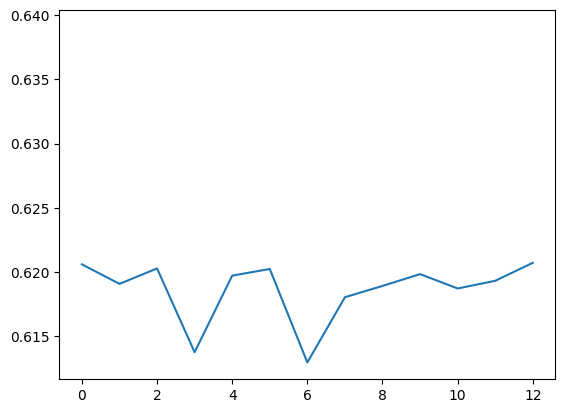

In [48]:
# 5-26. 훈련과 테스트 데이터의 정확도를 그래프로 확인
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

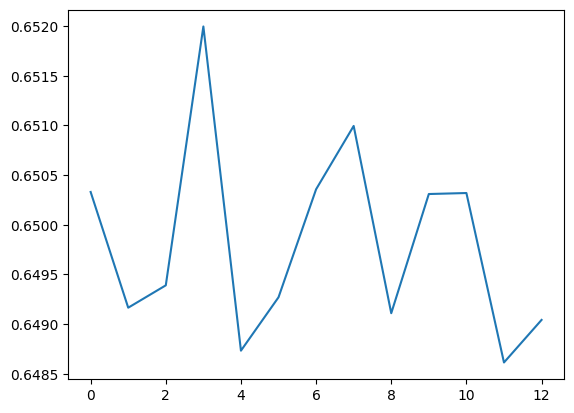

In [49]:
# 5-27. 훈련 데이터와 오차에 대한 그래프 확인
plt.plot(train_loss_hist)
plt.show()

- 그림 5-38은 훈련 데이터에 대해 에포크가 진행될 때마다 오차를 출력한 결과

- 에포크가 진행될수록 오차가 낮아지고 있음.



In [53]:
# 5-28. 예측 이미지 출력을 위한 전처리 함수
def im_convert(tensor):
  image=tensor.clone().detach().numpy()
  image=image.transpose(1, 2, 0)
  image=image*(np.array((0.5, 0.5, 0.5))+np.array((0.5, 0.5, 0.5)))
  image=image.clip(0,1)
  return image

- tensor.clone(): 기존 텐서의 내용을 복사한 텐서를 생성

- detach(): 기존 텐서에서 기울기가 전파되지 않은 텐서

- tensor.clone().detach(): 기존 텐서를 복사한 새로운 텐서 생성, 기울기에 영향 X

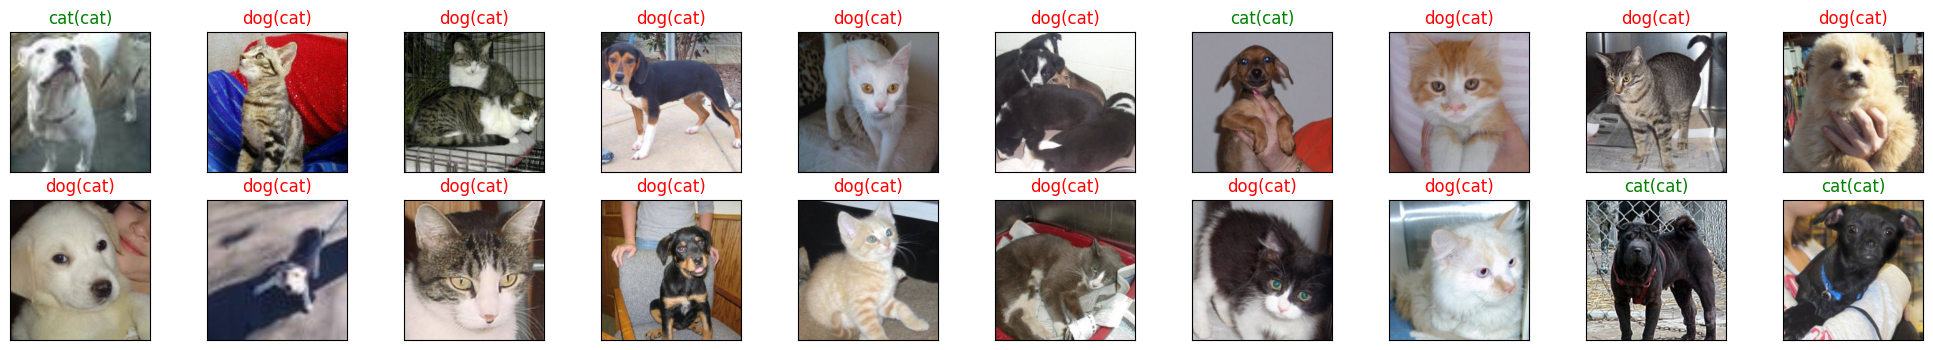

<Figure size 640x480 with 0 Axes>

In [54]:
# 5-29. 개와 고양이 예측 결과 출력
classes={0:'cat', 1:'dog'}

dataiter=iter(test_loader)
images, labels=next(dataiter)
output=model(images)
_, preds=torch.max(output, 1)

fig=plt.figure(figsize=(25, 4))
for idx in np.arange(20):
  ax=fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
  plt.imshow(im_convert(images[idx]))
  a.set_title(classes[labels[i].item()])
  ax.set_title("{}({})".format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])), color=("green" if preds[idx]==labels[idx] else "red"))
plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

- add_subplot; 한 화면에 여러 개의 이미지 담기 위해 사용

첫 번째 파라미터: 행의 수 (이미지를 두 줄로 출력)

두 번째 파라미터: 열의 수 (한 줄에 열 개의 이미지 출력)

세 번째 파라미터: 인덱스 (행, 열 기준으로 순차적으로 이미지 출력)

네 번째 파라미터: 틱(tick) 삭제



# 미세 조정 기법

미세 조정 기법: 사전 훈련된 모델, 합성곱층, 데이터 분류기의 가중치 업데이트하며 훈련시키는 방식

: 사전 학습된 모델을 목적에 맞게 재학습, 학습된 가중치의 일부 재학습

: 사전 훈련된 네트워크를 미세 조정하여 분석하려는 데이터셋에 잘 맞도록 모델의 파라미터 조정 기법

- 데이터셋이 크고 사전 훈련된 모델과 유사성이 작을 경우: 모델 전체 재학습

- 데이터셋이 크고 사전 훈련된 모델과 유사성이 클 경우: 합성곱층의 뒷부분, 데이터 분류기 학습, 합성곱층의 뒷부분과 데이터 분류기만 새로 학습하더라도 최적의 성능

- 데이터셋이 작고 사전 훈련된 모델과 유사성이 작을 경우: 합성곱층의 일부분, 데이터 분류기 학습

- 데이터셋이 작고 사전 훈련된 모델과 유사성이 클 경우: 데이터 분류기만 학습. 최종 데이터 분류기인 완전연결층에 대해서만 미세 조정 기법 적용

